# 04 Report: do clickbait title tactics go with views and engagement?
Run these first (each writes CSVs to `reports/`):
`scripts/run_comparison.py` (FT-3), `scripts/run_effects.py` (FR-7), `scripts/run_tfidf_model.py`.

Data: trending YouTube videos in the US, GB and CA, 78,180 English titles. Everything here is
**correlation among videos that made the trending list**, not a causal effect of editing a title.

**Short answer** (details and numbers below):
1. Titles carry some signal, but much of it is topic, format and creator style, not tactics.
2. Within the same creator, **no tactic clearly raises views**. Exclamation marks and clickbait
   phrases go with slightly *fewer* views.
3. In the pooled data several tactics (hashtags, caps, `|` or `:`, emoji) look helpful. Almost all
   of that is which channels use them.
4. Numbers in titles go with fewer likes and comments per view.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ytclickbait.config import load_config
from ytclickbait.report import backlash, pooled_vs_within, rank_tactics

cfg = load_config()
reports = cfg.root / "reports"
fig_dir = cfg.path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

comparison = pd.read_csv(reports / "model_comparison.csv")
effects = pd.read_csv(reports / "effects.csv")
usage = pd.read_csv(reports / "usage_rates.csv")

HELPS, HURTS, NONE = "#2166ac", "#d95f02", "#9a9a9a"  # colorblind-safe
COLORS = {"helps": HELPS, "hurts": HURTS, "no clear effect": NONE, "not estimated": NONE}
sns.set_theme(style="whitegrid", font_scale=0.95)


def save(name):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Which title representation predicts best? (FT-3)
Ridge on [title features + the same controls], scored on held-out videos. The floor is
**controls only**. The gain over it is the title's contribution.

- `split_group` (**primary**): test channels never seen in training. Can the title help for a
  new creator?
- `split_time`: same channels, later videos, with the channel's usual views as a control. The
  fairest estimate of what the title adds beyond the creator.

In [2]:
r2 = comparison.pivot_table(index="model", columns=["split", "target"], values="r2")
order = ["controls only", "rules", "rules + sentiment", "tfidf", "embeddings", "rules + embeddings"]
r2.loc[order].round(3)

split                        split_group                               \
target             log_comments_per_view log_likes_per_view log_views   
model                                                                   
controls only                      0.098              0.247     0.315   
rules                              0.124              0.296     0.331   
rules + sentiment                  0.132              0.299     0.331   
tfidf                              0.252              0.395     0.416   
embeddings                         0.192              0.356     0.379   
rules + embeddings                 0.198              0.366     0.382   

split                         split_time                               
target             log_comments_per_view log_likes_per_view log_views  
model                                                                  
controls only                      0.043              0.373     0.635  
rules                              0.061              0.422     0.638  
rules + sentiment                  0.072              0.422     0.638  
tfidf                              0.314              0.625     0.650  
embeddings                         0.171              0.499     0.649  
rules + embeddings                 0.176              0.508     0.650

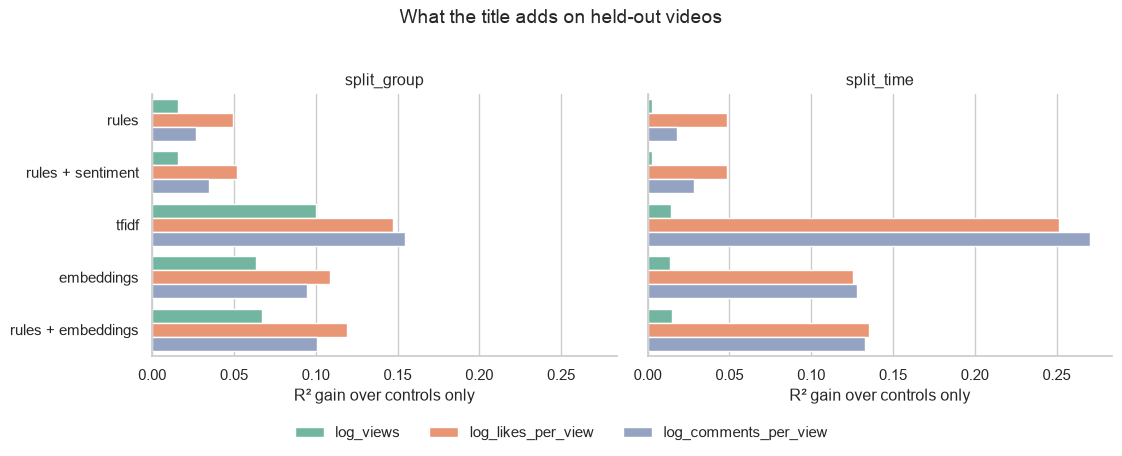

In [3]:
gain = comparison[comparison["model"] != "controls only"]
g = sns.catplot(
    data=gain,
    y="model",
    x="r2_gain_vs_controls",
    hue="target",
    col="split",
    kind="bar",
    order=order[1:],
    height=4,
    aspect=1.15,
    palette="Set2",
)
g.set_titles("{col_name}")
g.set_axis_labels("R² gain over controls only", "")
g.figure.suptitle("What the title adds on held-out videos", y=1.03)
sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, 0.02), ncol=3, title=None)
save("01_model_comparison")

**Reading it.** The 14 rule features add little (about +0.016 R² for views on new creators,
+0.002 within a creator). TF-IDF and embeddings add more for new creators because words and
sentence vectors also encode topic, series and creator. The cleanest title-only number is the
`split_time` views row: every model adds roughly 0.00 to 0.015 R². Engagement gains are larger
but are mostly topic and format (for example "trailer", "mv", "highlights"), not tactics.

## 2. Which tactics go with views? (FR-7 and FR-9)
OLS on the 14 rule features with controls, 95% CIs clustered by channel. **Within creator**
means each variable has its channel's mean removed first (channel fixed effects). Effects are
per **1 standard deviation** of the feature so tactics can be compared. A tactic "helps" or
"hurts" only if its CI excludes zero.

In [4]:
rank = rank_tactics(effects, usage, "log_views", model="fixed_effects")
rank[
    ["feature", "std_coef", "std_ci_low", "std_ci_high", "pct_effect", "usage_rate", "verdict"]
].round(4)

,feature,std_coef,std_ci_low,std_ci_high,pct_effect,usage_rate,verdict
0,caps_ratio,0.0162,-0.0024,0.0349,6.7651,0.1586,no clear effect
1,has_brackets,0.0096,-0.0054,0.0246,2.4738,0.1920,no clear effect
2,has_hashtag,0.0083,-0.0175,0.0340,4.1660,0.0428,no clear effect
3,n_emoji,0.0050,-0.0034,0.0134,1.2437,0.0522,no clear effect
4,starts_with_number,0.0009,-0.0057,0.0076,0.5767,0.0262,no clear effect
5,has_second_person,-0.0020,-0.0073,0.0033,-0.9782,0.0426,no clear effect
6,has_number,-0.0036,-0.0163,0.0091,-0.7365,0.3852,no clear effect
7,n_question,-0.0059,-0.0128,0.0010,-1.3338,0.0494,no clear effect
8,n_exclaim,-0.0089,-0.0173,-0.0004,-1.4635,0.1888,hurts
9,has_pipe_or_colon,-0.0093,-0.0226,0.0040,-1.9476,0.3405,no clear effect


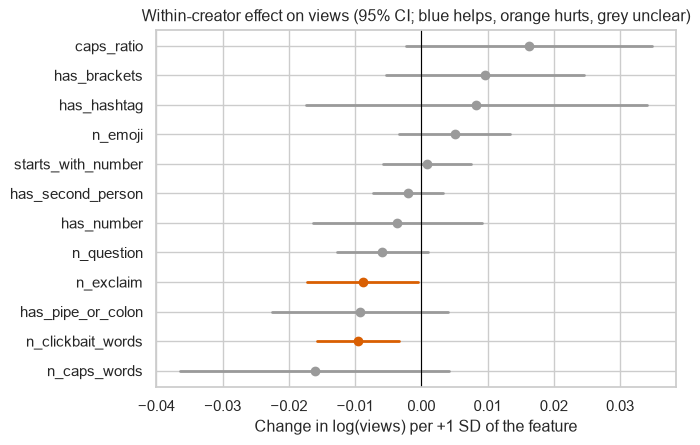

In [5]:
def forest(rank, title, name, xlabel):
    d = rank.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4.6))
    y = np.arange(len(d))
    for yi, (_, r) in zip(y, d.iterrows(), strict=True):
        ax.plot([r.std_ci_low, r.std_ci_high], [yi, yi], color=COLORS[r.verdict], lw=2)
        ax.plot(r.std_coef, yi, "o", color=COLORS[r.verdict])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y, d["feature"])
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    save(name)


forest(
    rank,
    "Within-creator effect on views (95% CI; blue helps, orange hurts, grey unclear)",
    "02_tactics_views_within_creator",
    "Change in log(views) per +1 SD of the feature",
)

## 3. Which tactics only looked good because of who uses them?
Pooled model vs within-creator model. A tactic whose effect shrinks toward zero or flips sign
was about **which channels use it**, not the tactic. This is the answer to "pooled model vs.
single-creator model".

In [6]:
pv = pooled_vs_within(effects, "log_views")
pv.round(3)

,feature,pooled,within,pooled_verdict,within_verdict,sign_flip,confounded,shrink
0,has_hashtag,0.109,0.008,helps,no clear effect,False,True,0.924
1,caps_ratio,0.091,0.016,helps,no clear effect,False,True,0.821
2,has_pipe_or_colon,0.066,-0.009,helps,no clear effect,True,True,0.859
3,n_emoji,0.035,0.005,helps,no clear effect,False,True,0.858
4,has_second_person,0.012,-0.002,helps,no clear effect,True,True,0.838
5,has_number,0.012,-0.004,no clear effect,no clear effect,True,False,0.699
6,has_brackets,0.010,0.010,no clear effect,no clear effect,False,False,0.019
7,starts_with_number,-0.002,0.001,no clear effect,no clear effect,True,False,0.557
8,n_question,-0.019,-0.006,no clear effect,no clear effect,False,False,0.683
9,n_clickbait_words,-0.031,-0.010,hurts,hurts,False,False,0.692


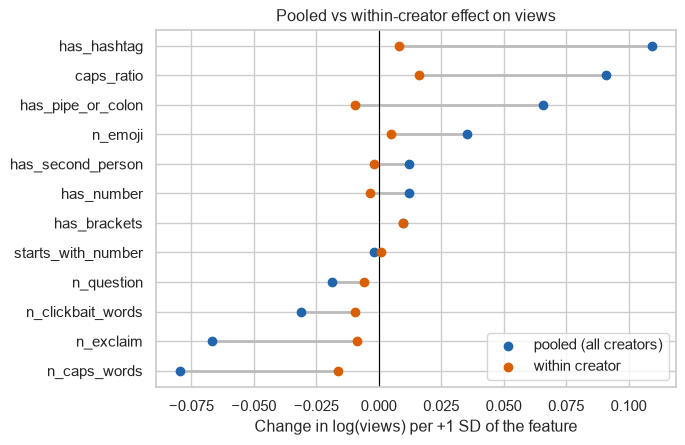

In [7]:
d = pv.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
y = np.arange(len(d))
ax.hlines(y, d["within"], d["pooled"], color="#bbbbbb", lw=2)
ax.scatter(d["pooled"], y, color=HELPS, label="pooled (all creators)", zorder=3)
ax.scatter(d["within"], y, color=HURTS, label="within creator", zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y, d["feature"])
ax.set_xlabel("Change in log(views) per +1 SD of the feature")
ax.set_title("Pooled vs within-creator effect on views")
ax.legend(loc="lower right")
save("03_pooled_vs_within")

## 4. Most overused tactics (FR-9)
**Overused** = common (used in at least 10% of titles) but with no clear positive effect on
views within creator. The point is where creators spend effort for no measurable gain.

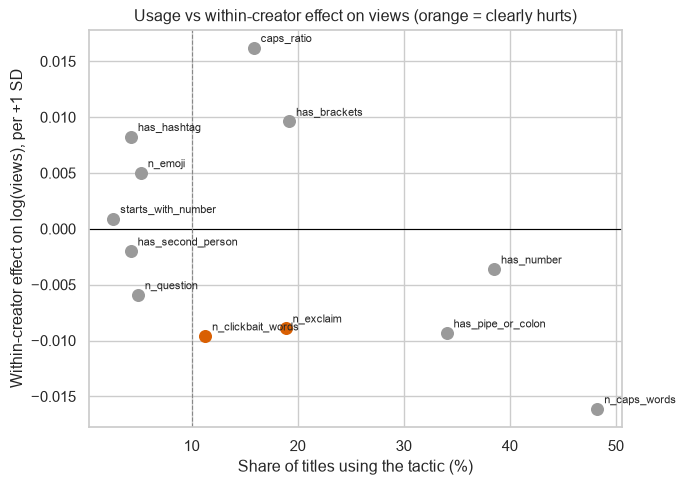

,feature,usage_rate,std_coef,verdict
0,caps_ratio,0.159,0.016,no clear effect
1,has_brackets,0.192,0.010,no clear effect
6,has_number,0.385,-0.004,no clear effect
8,n_exclaim,0.189,-0.009,hurts
9,has_pipe_or_colon,0.340,-0.009,no clear effect
10,n_clickbait_words,0.113,-0.010,hurts
11,n_caps_words,0.483,-0.016,no clear effect


In [8]:
r = rank_tactics(effects, usage, "log_views", model="fixed_effects")
fig, ax = plt.subplots(figsize=(7, 5))
for _, row in r.iterrows():
    ax.scatter(row.usage_rate * 100, row.std_coef, s=70, color=COLORS[row.verdict], zorder=3)
    ax.annotate(
        row.feature,
        (row.usage_rate * 100, row.std_coef),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )
ax.axhline(0, color="black", lw=0.8)
ax.axvline(10, color="#888888", ls="--", lw=0.8)
ax.set_xlabel("Share of titles using the tactic (%)")
ax.set_ylabel("Within-creator effect on log(views), per +1 SD")
ax.set_title("Usage vs within-creator effect on views (orange = clearly hurts)")
save("04_overused")
r.loc[r["overused"], ["feature", "usage_rate", "std_coef", "verdict"]].round(3)

## 5. Do tactics that raise views cost likes or comments? (engagement backlash)
Same within-creator model for `log_likes_per_view` and `log_comments_per_view`. Engagement is
skipped (not zero) when the creator turned likes or comments off. `*` marks a CI that excludes
zero.

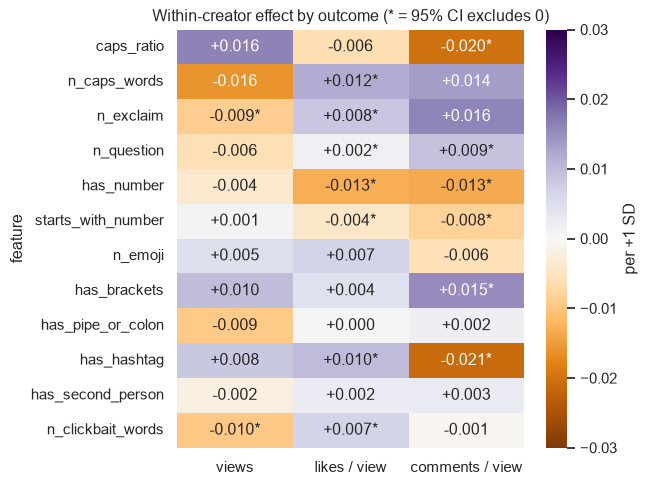

Tactics that clearly help views but clearly hurt engagement: []


In [9]:
bl = backlash(effects)
cols = ["std_log_views", "std_log_likes_per_view", "std_log_comments_per_view"]
sig = pd.DataFrame(
    {c: bl[f"verdict_{c.replace('std_', '')}"].isin(["helps", "hurts"]) for c in cols}
).to_numpy()
vals = bl[cols].to_numpy()
annot = np.array(
    [
        [f"{v:+.3f}{'*' if s else ''}" for v, s in zip(rv, rs, strict=True)]
        for rv, rs in zip(vals, sig, strict=True)
    ]
)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    pd.DataFrame(vals, index=bl["feature"], columns=["views", "likes / view", "comments / view"]),
    annot=annot,
    fmt="",
    cmap="PuOr",
    center=0,
    vmin=-0.03,
    vmax=0.03,
    cbar_kws={"label": "per +1 SD"},
    ax=ax,
)
ax.set_title("Within-creator effect by outcome (* = 95% CI excludes 0)")
save("05_engagement")
print(
    "Tactics that clearly help views but clearly hurt engagement:",
    list(bl.loc[bl["backlash"], "feature"]),
)

## 6. Does it differ by category?
Within-creator effect on views in the 10 largest categories. Mostly grey: with fewer videos
per category the CIs widen. Treat the starred cells as leads, since we test many cells and
roughly 1 in 20 would appear by chance.

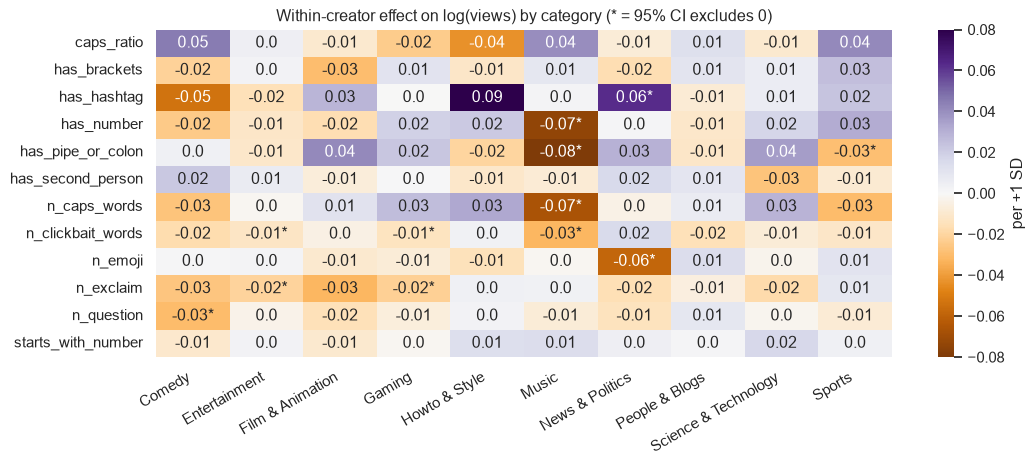

In [10]:
cat = effects[
    (effects["target"] == "log_views")
    & (effects["model"] == "fixed_effects")
    & (effects["scope"] != "overall")
    & (effects["feature"] != "n_chars")
    & (effects["feature"] != "n_words")
].copy()
cat["sig"] = (cat["ci_low"] > 0) | (cat["ci_high"] < 0)
coef = cat.pivot(index="feature", columns="scope", values="std_coef")
star = cat.pivot(index="feature", columns="scope", values="sig")
annot = (coef.round(2) + 0.0).astype(str) + star.map(lambda s: "*" if s else "")
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(
    coef,
    annot=annot,
    fmt="",
    cmap="PuOr",
    center=0,
    vmin=-0.08,
    vmax=0.08,
    cbar_kws={"label": "per +1 SD"},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Within-creator effect on log(views) by category (* = 95% CI excludes 0)")
plt.xticks(rotation=30, ha="right")
save("06_by_category")

## Findings
- **Prediction.** Rule features alone add little over controls; TF-IDF and embeddings add more
  but mostly through topic and creator style.
- **No tactic clearly raises views within a creator.** Exclamation marks and clickbait phrases go
  with slightly fewer views. Common tactics with no measurable gain (overused): caps, brackets,
  numbers, `|` or `:`, and capitalized words (plus exclamation marks and clickbait phrases,
  which clearly hurt).
- **Pooled results mislead.** Hashtags, caps, `|` or `:`, emoji and second person look helpful
  when all creators are pooled, but more than 80% of that effect disappears within creator.
- **Engagement.** Numbers in titles (and titles that start with a number) go with fewer likes and
  comments per view. Exclamation marks and clickbait phrases go with slightly more likes per view.
  No tactic clearly helps views while hurting engagement, so the data do not show the classic
  "clickbait backlash" pattern.
- **Categories.** Effects are mostly unclear within categories; Music shows the most negative
  tactics (numbers, `|` or `:`, caps words).

## Limitations
- Trending videos only; effects may differ for videos that never trend.
- Correlation, not causation: thumbnail, video length, subscriber count and promotion are not in
  the data. The within-creator model removes stable creator differences only.
- Effects are small (about 0.01 to 0.03 log-views per SD). Many of them are within sampling noise.
- We test 14 tactics across 3 outcomes and 11 scopes; some "significant" cells are chance.
- Fixed-effect standard errors do not adjust degrees of freedom for the absorbed channel means.
  With about 12,000 channels the difference is small.

## 7. What topics and formats do title embeddings group together? (FR-12)

Eight k-means clusters were fitted on the 63,437 `split_group` training videos with seed 42.
The controls-only Ridge was fitted on those training videos using channel-grouped
cross-validation (selected alpha 100). Cluster size counts all assigned videos. Mean
residuals use only the 14,743 held-out videos and equal observed `log_views` minus the
controls-only prediction.

| Cluster | Topic or format suggested by representative titles |
|---|---|
| 1 | Car challenges and project reveals |
| 2 | Golf and basketball highlights |
| 3 | Lifestyle vlogs and makeovers |
| 4 | Manchester United match highlights |
| 5 | Official music videos |
| 6 | Boxing face-offs and post-fight coverage |
| 7 | Minecraft stories and challenges |
| 8 | Game and film trailers |

These labels describe the five member videos nearest each centroid in Euclidean distance.
The residuals describe how each title group fared relative to the model on held-out
channels. Positive values indicate more views than the model predicted on the log scale.

The full table is in [embedding_clusters.csv](../reports/embedding_clusters.csv).
Regenerate it with `uv run python scripts/run_embedding_clusters.py`.


In [ ]:
pd.read_csv(reports / "embedding_clusters.csv").round(3)